# Parallel quicksort benchmarking

## Setup

In [1]:
import platform
import re
import subprocess
from datetime import datetime
from pathlib import Path
from typing import Optional, Sequence

REPO_ROOT = Path.cwd()
BINARY = REPO_ROOT / 'src' / 'parallelQuicksort'
DATA_ROOT = REPO_ROOT / 'data'

# CSV column -> label the binary prints for that sort; also fixes the column order.
SORTS = {
	'Seq': 'Sequential',
	'Par': 'Parallel',
	'Libc': 'Built-in',
}

TIMING = re.compile(r'^(\S+) quicksort took: ([\d.]+) sec\.$')


def machine_name() -> str:
	'''The DNS hostname follows whichever network we are on, so on macOS take the
	stable local name instead to keep one directory per machine, not per network.'''
	if platform.system() != 'Darwin':
		return platform.node()

	local_name = subprocess.run(
		['scutil', '--get', 'LocalHostName'],
		capture_output=True, text=True, check=True,
	).stdout.strip()
	return f'{local_name}.local'


def time_quicksorts(size: int) -> dict:
	output = subprocess.run(
		[BINARY, str(size)],
		capture_output=True, text=True, check=True,
	).stdout
	timings = dict(TIMING.match(line).groups() for line in output.splitlines())
	return {
		'Size': size,
		**{column: float(timings[label]) for column, label in SORTS.items()},
	}


def write_wide_csv(records: list, output_path: Path) -> None:
	output_path.parent.mkdir(parents=True, exist_ok=True)
	with output_path.open('w') as csv_file:
		csv_file.write(', '.join(['Size', *SORTS]) + '\n')
		for record in records:
			row = [str(record['Size']), *(f'{record[column]:.6f}' for column in SORTS)]
			csv_file.write(', '.join(row) + '\n')


def run_benchmark(
	sizes: Sequence[int] = (100, 1_000, 10_000, 100_000, 1_000_000),
	reps: int = 5,
	output_path: Optional[Path] = None,
) -> list:
	if output_path is None:
		now = datetime.now()
		output_path = (
			DATA_ROOT
			/ f'{machine_name()}_{now:%Y-%m-%d}'
			/ f'measurements_{now:%H:%M}_wide.csv'
		)

	records = [
		time_quicksorts(size)
		for size in sizes
		for _ in range(reps)
	]
	write_wide_csv(records, output_path)
	print(f'{len(records)} measurements -> {output_path}')
	return records

In [2]:
import numpy as np
import matplotlib.pyplot as plt


class Analysis:
	'''Bootstrap rather than a t interval: no scipy here for the t quantile, and
	timing distributions are right-skewed so the normal assumption is unearned.
	Resampling whole reps keeps the three sorts paired, as they are measured
	together on one array in a single process.'''

	def __init__(self, data: list, resamples: int = 10_000, level: float = 0.95):
		grouped = {}
		for record in data:
			grouped.setdefault(record['Size'], []).append(record)

		self.columns = list(SORTS)
		self.sizes = np.array(sorted(grouped))
		self.reps = len(grouped[self.sizes[0]])
		self.level = level

		samples = np.array([
			[[record[column] for column in self.columns] for record in grouped[size]]
			for size in self.sizes
		])
		self._means = samples.mean(axis=1)

		rng = np.random.default_rng(0)
		indices = rng.integers(self.reps, size=(resamples, self.reps))
		self._resampled = samples[:, indices, :].mean(axis=2)

	def _interval(self, resampled: np.ndarray) -> np.ndarray:
		tail = 100 * (1 - self.level) / 2
		return np.percentile(resampled, [tail, 100 - tail], axis=1)

	def mean(self, column: str) -> np.ndarray:
		return self._means[:, self.columns.index(column)]

	def interval(self, column: str) -> np.ndarray:
		return self._interval(self._resampled[:, :, self.columns.index(column)])

	def speedup(self, baseline: str) -> tuple:
		against = self.columns.index(baseline)
		parallel = self.columns.index('Par')
		ratios = self._resampled[:, :, against] / self._resampled[:, :, parallel]
		return self.mean(baseline) / self.mean('Par'), self._interval(ratios)


## Measurements

Size grid is log-spaced and refined between 1e5 and 1e6, where the parallel
version overtakes the sequential one.

Caveat: the binary seeds with `srand(time(NULL))`, which has one-second
resolution, so reps falling in the same second sort the *identical* array. At the
small sizes these reps measure timer noise, not input variability, and the
intervals below are correspondingly optimistic.

In [3]:
data = run_benchmark(reps=15, sizes=[
	100, 300, 1_000, 3_000, 10_000, 30_000,
	100_000, 200_000, 300_000, 500_000, 700_000, 1_000_000,
])
analysis = Analysis(data)

180 measurements -> /Users/simon/ENSIMAG/M2R-ParallelQuicksort/data/mightbesimon.local_2026-11-10/measurements_16:21_wide.csv


In [4]:
data

[{'Size': 100, 'Seq': 6e-06, 'Par': 0.001766, 'Libc': 6e-06},
 {'Size': 100, 'Seq': 6e-06, 'Par': 0.001849, 'Libc': 6e-06},
 {'Size': 100, 'Seq': 6e-06, 'Par': 0.001573, 'Libc': 5e-06},
 {'Size': 100, 'Seq': 5e-06, 'Par': 0.001604, 'Libc': 5e-06},
 {'Size': 100, 'Seq': 6e-06, 'Par': 0.001364, 'Libc': 7e-06},
 {'Size': 100, 'Seq': 6e-06, 'Par': 0.001559, 'Libc': 5e-06},
 {'Size': 100, 'Seq': 6e-06, 'Par': 0.001597, 'Libc': 7e-06},
 {'Size': 100, 'Seq': 6e-06, 'Par': 0.001548, 'Libc': 7e-06},
 {'Size': 100, 'Seq': 6e-06, 'Par': 0.001918, 'Libc': 9e-06},
 {'Size': 100, 'Seq': 7e-06, 'Par': 0.002618, 'Libc': 6e-06},
 {'Size': 100, 'Seq': 6e-06, 'Par': 0.00167, 'Libc': 7e-06},
 {'Size': 100, 'Seq': 6e-06, 'Par': 0.001564, 'Libc': 5e-06},
 {'Size': 100, 'Seq': 6e-06, 'Par': 0.001167, 'Libc': 6e-06},
 {'Size': 100, 'Seq': 6e-06, 'Par': 0.001188, 'Libc': 7e-06},
 {'Size': 100, 'Seq': 5e-06, 'Par': 0.001142, 'Libc': 7e-06},
 {'Size': 300, 'Seq': 1.9e-05, 'Par': 0.003392, 'Libc': 2.9e-05},
 {'Si

## Summary

In [5]:
columns = ''.join(f'{SORTS[column]:>22}' for column in analysis.columns)
print(f"{'Size':>9}{columns}{'Par vs Built-in':>24}")

for row, size in enumerate(analysis.sizes):
	cells = ''
	for column in analysis.columns:
		low, high = analysis.interval(column)[:, row]
		cells += f'{analysis.mean(column)[row]:>13.6f} ±{(high - low) / 2:<8.6f}'
	speedup, (low, high) = analysis.speedup('Libc')
	print(f'{size:>9}{cells}{speedup[row]:>10.2f}  [{low[row]:.2f}, {high[row]:.2f}]')

     Size            Sequential              Parallel              Built-in         Par vs Built-in
      100     0.000006 ±0.000000     0.001608 ±0.000178     0.000006 ±0.000001      0.00  [0.00, 0.00]
      300     0.000018 ±0.000000     0.004109 ±0.000173     0.000024 ±0.000001      0.01  [0.01, 0.01]
     1000     0.000071 ±0.000001     0.005626 ±0.000326     0.000076 ±0.000002      0.01  [0.01, 0.01]
     3000     0.000269 ±0.000014     0.010235 ±0.000841     0.000246 ±0.000012      0.02  [0.02, 0.03]
    10000     0.001068 ±0.000083     0.010933 ±0.000954     0.000900 ±0.000018      0.08  [0.08, 0.09]
    30000     0.003246 ±0.000102     0.018889 ±0.003985     0.003166 ±0.000142      0.17  [0.13, 0.20]
   100000     0.011312 ±0.000028     0.020852 ±0.000731     0.011044 ±0.000053      0.53  [0.51, 0.55]
   200000     0.024499 ±0.000231     0.026521 ±0.000812     0.023213 ±0.000079      0.88  [0.85, 0.90]
   300000     0.037715 ±0.000757     0.030792 ±0.001302     0.036899 ±0.0013

## Time against size

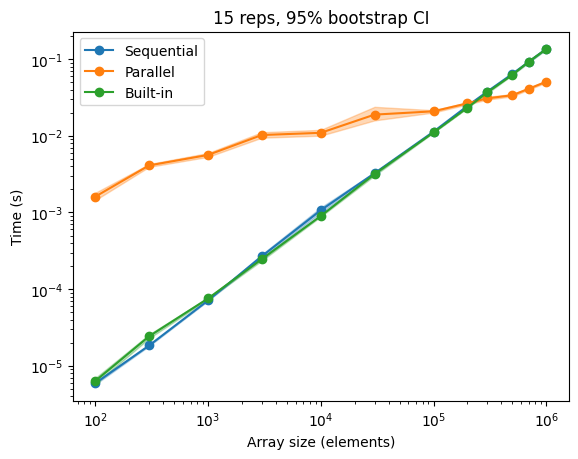

In [6]:
axes = plt.subplots()[1]

for index, column in enumerate(analysis.columns):
	low, high = analysis.interval(column)
	axes.fill_between(analysis.sizes, low, high, color=f'C{index}', alpha=0.3)
	axes.plot(analysis.sizes, analysis.mean(column), 'o-',
		color=f'C{index}', label=SORTS[column])

axes.set(
	xscale='log', yscale='log',
	xlabel='Array size (elements)', ylabel='Time (s)',
	title=f'{analysis.reps} reps, 95% bootstrap CI',
)
axes.legend()
plt.show()

## Speedup against both sequential baselines

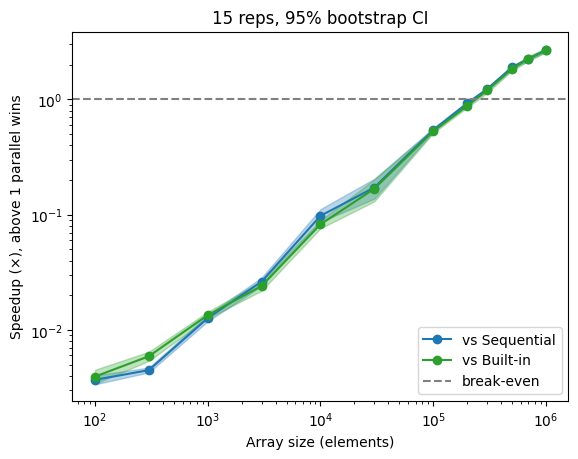

In [7]:
axes = plt.subplots()[1]

for baseline in ('Seq', 'Libc'):
	index = analysis.columns.index(baseline)
	speedup, (low, high) = analysis.speedup(baseline)
	axes.fill_between(analysis.sizes, low, high, color=f'C{index}', alpha=0.3)
	axes.plot(analysis.sizes, speedup, 'o-',
		color=f'C{index}', label=f'vs {SORTS[baseline]}')

axes.axhline(1, linestyle='--', color='grey', label='break-even')
axes.set(
	xscale='log', yscale='log',
	xlabel='Array size (elements)', ylabel='Speedup (×), above 1 parallel wins',
	title=f'{analysis.reps} reps, 95% bootstrap CI',
)
axes.legend()
plt.show()

above 1 (10^0) means parallel is faster

## Distribution of repetitions

100 reps at the two extremes of the grid: n = 1,000, where the thread pool
dominates and the parallel timings scatter, and n = 1,000,000, where it has
amortised and all three settle down.

Each group is divided by its own median so the spreads are comparable despite
the times differing by four orders of magnitude.

The two sizes do not measure the same kind of variability. A rep at n = 1,000
takes ~0.01 s, so all 100 fall within one or two ticks of `time(NULL)` and sort
near enough the same array -- that spread is scheduler noise alone. A rep at
n = 1,000,000 takes ~0.33 s, so each one reseeds and sorts a different array,
and its spread includes genuine input variation.

In [8]:
data_detail = run_benchmark(reps=100, sizes=[1_000, 1_000_000])

200 measurements -> /Users/simon/ENSIMAG/M2R-ParallelQuicksort/data/mightbesimon.local_2026-11-10/measurements_16:21_wide.csv


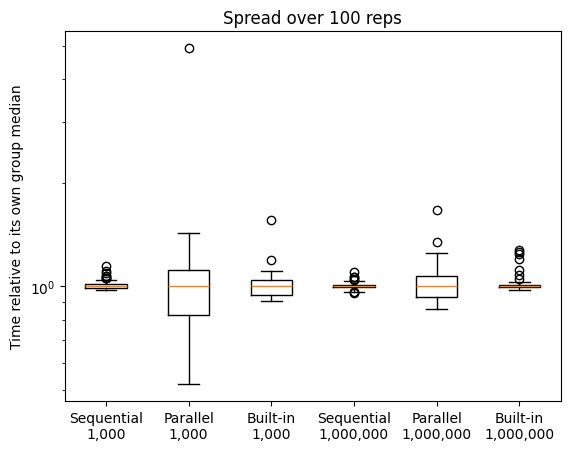

In [9]:
axes = plt.subplots()[1]

groups = []
labels = []
for size in sorted({record['Size'] for record in data_detail}):
	for column in SORTS:
		times = np.array([
			record[column] for record in data_detail if record['Size'] == size
		])
		groups.append(times / np.median(times))
		labels.append(f'{SORTS[column]}\n{size:,}')

axes.boxplot(groups, tick_labels=labels)
axes.set(
	yscale='log', ylabel='Time relative to its own group median',
	title='Spread over 100 reps',
)
plt.show()

## Comparing machines

Teodor ran the original coarse grid, so the comparison is on the five sizes both
machines have. His five reps per size make for a crude bootstrap interval -- wide
bands on his curve are thin evidence, not real instability.

In [10]:
teodor_path = Path(
	'data/Teodors-MacBook-Pro.local_2026-11-10/measurements_14:01_wide.csv'
)

teodor_records = [
	{'Size': int(size), **dict(zip(SORTS, map(float, times)))}
	for size, *times in (
		row.split(', ') for row in teodor_path.read_text().splitlines()[1:]
	)
]

shared_sizes = {record['Size'] for record in teodor_records} & {
	record['Size'] for record in data
}
machines = {
	machine_name(): Analysis(
		[record for record in data if record['Size'] in shared_sizes]
	),
	teodor_path.parent.name.split('_')[0]: Analysis(
		[record for record in teodor_records if record['Size'] in shared_sizes]
	),
}

for name, machine in machines.items():
	print(f'{name}: {len(machine.sizes)} sizes, {machine.reps} reps')

mightbesimon.local: 5 sizes, 15 reps
Teodors-MacBook-Pro.local: 5 sizes, 5 reps


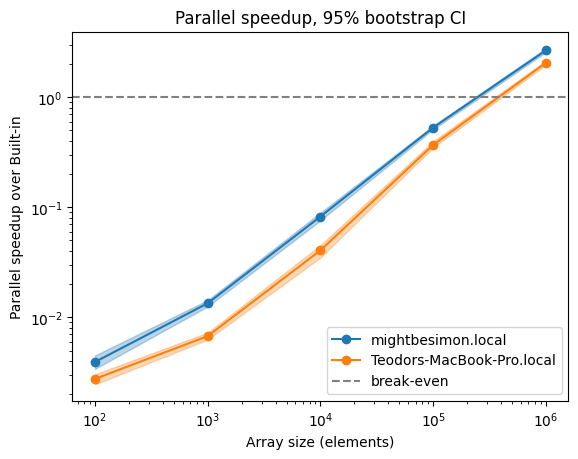

In [11]:
axes = plt.subplots()[1]

for index, (name, machine) in enumerate(machines.items()):
	speedup, (low, high) = machine.speedup('Libc')
	axes.fill_between(machine.sizes, low, high, color=f'C{index}', alpha=0.3)
	axes.plot(machine.sizes, speedup, 'o-', color=f'C{index}', label=name)

axes.axhline(1, linestyle='--', color='grey', label='break-even')
axes.set(
	xscale='log', yscale='log',
	xlabel='Array size (elements)', ylabel='Parallel speedup over Built-in',
	title='Parallel speedup, 95% bootstrap CI',
)
axes.legend()
plt.show()

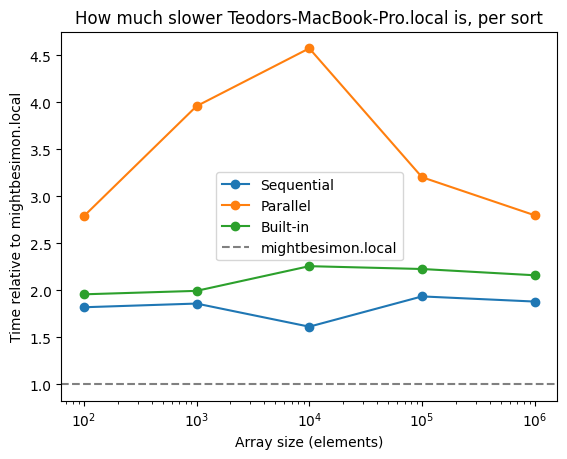

In [12]:
reference, other = machines

axes = plt.subplots()[1]
for index, column in enumerate(SORTS):
	axes.plot(
		machines[reference].sizes,
		machines[other].mean(column) / machines[reference].mean(column),
		'o-', color=f'C{index}', label=SORTS[column],
	)

axes.axhline(1, linestyle='--', color='grey', label=reference)
axes.set(
	xscale='log',
	xlabel='Array size (elements)', ylabel=f'Time relative to {reference}',
	title=f'How much slower {other} is, per sort',
)
axes.legend()
plt.show()